In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Collect the Data

In [36]:
df = pd.read_csv("noisy_curvefit_data.csv")
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Shape: (100, 6)
Rows: 100
Columns: 6


In [37]:
df.head()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
0,-1.000000,11.624419,8.296963,12.201067,7.811725,3.155566
1,-0.929293,10.377466,9.674440,12.198084,8.275006,7.518855
2,-0.858586,10.585100,9.251983,13.186565,12.926586,9.963630
3,-0.787879,10.913928,7.786344,12.552304,11.832379,9.625801
4,-0.717172,8.640287,8.551869,4.741432,8.790834,6.624113


In [38]:
df.tail()

,x,y_noise_1,y_noise_2,y_noise_3,y_noise_4,y_noise_5
95,5.717172,-1.411918,0.822231,-2.027132,-1.825106,2.746147
96,5.787879,0.344879,-1.718956,2.747559,-6.803779,-5.137472
97,5.858586,0.307133,0.353528,0.967976,5.461567,-0.905616
98,5.929293,0.048657,0.159961,2.482130,-0.414616,-4.334548
99,6.000000,-0.193438,-2.244792,1.930035,4.992414,-6.872850


In [39]:
print(list(df.columns))

['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5']


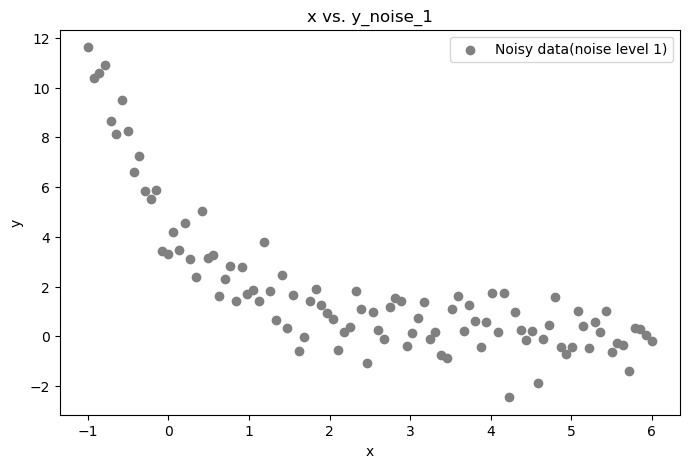

In [40]:
plt.figure(figsize=(8,5))
plt.scatter(df["x"], df["y_noise_1"], color="gray", label="Noisy data(noise level 1)")
plt.xlabel("x")
plt.ylabel("y")
plt.title("x vs. y_noise_1")
plt.legend()
plt.show()

# Fit the Data

In [41]:
x = df["x"]
y_noise_1 = df["y_noise_1"]

In [42]:
def model(x, A, k):
    return A * np.exp(-k * x)

In [43]:
p0 = [1, 1]
popt, pcov = curve_fit(model, x, y_noise_1, p0=p0)
A_fit, k_fit = popt
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

Fit: y = 4.71 * e^(-0.92 * x)


In [44]:
residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

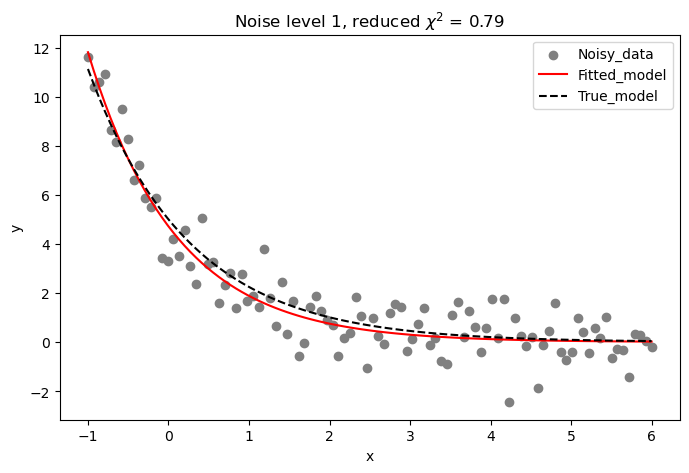

In [45]:
plt.figure(figsize=(8,5))
plt.scatter(x, y_noise_1, color="gray", label="Noisy_data")
plt.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted_model")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True_model")
plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise level 1, reduced $\\chi^2$ = {chi2_reduced:.2f}")
plt.legend()
plt.show()

# Compare Different Noise Levels

In [46]:
def fit_model(x, y):
    popt, pcov = curve_fit(model, x, y, p0=[1, 1])
    residuals = y-model(x, *popt)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    return popt, chi2_reduced

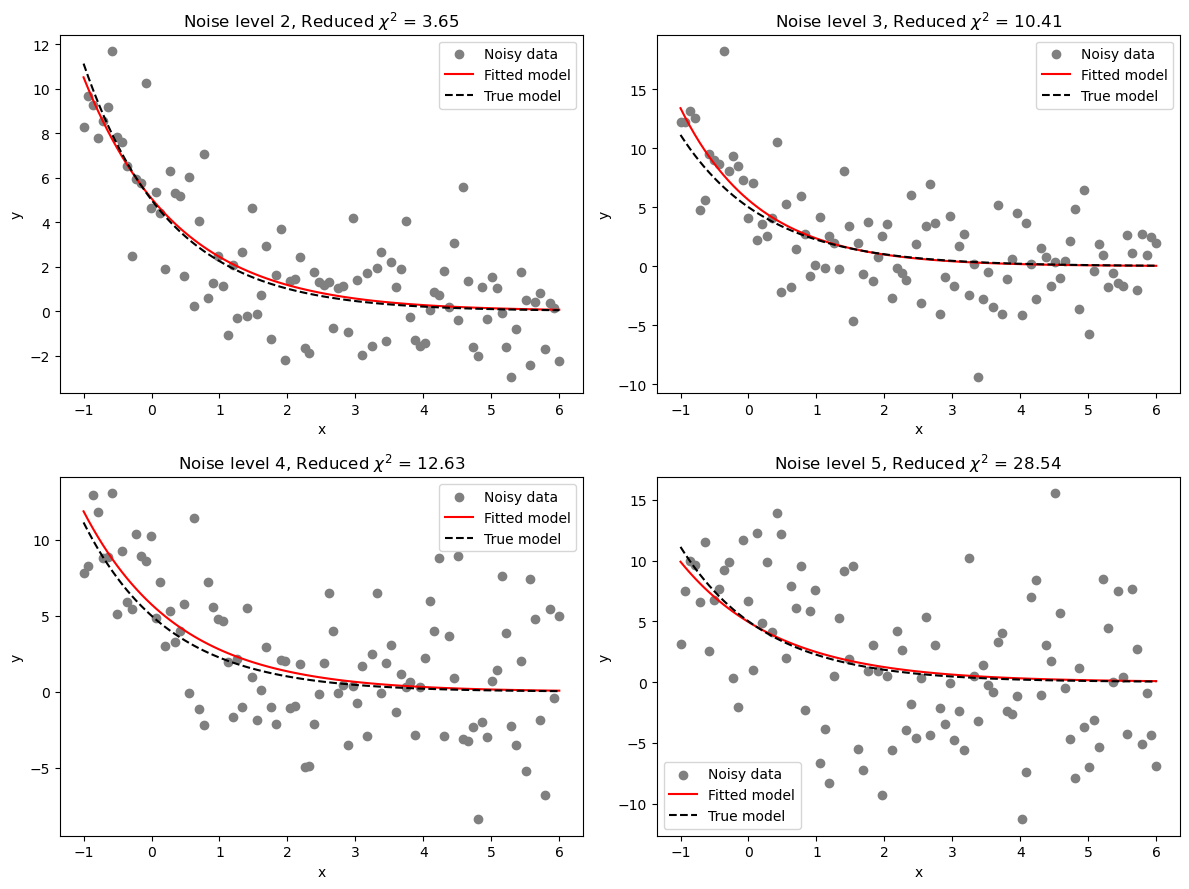

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()
noise_levels = [2, 3, 4, 5]
for ax, level in zip(axes, noise_levels):
    y = df[f"y_noise_{level}"]
    popt, chi2_reduced = fit_model(x, y)
    A_fit, k_fit = popt
    ax.scatter(x, y, color="gray", label="Noisy data")
    ax.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted model")
    ax.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True model")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(f"Noise level {level}, Reduced $\\chi^2$ = {chi2_reduced:.2f}")
    ax.legend()
plt.tight_layout()
plt.show()

In [48]:
'''
4: The black dotted line never changes because its the true model that doesn't depend on the data. 
The red dotted line is fit to the noisy points so it slowly drifts away from the black line as the noise increases. 

The reduced chi-squared increases as the noise level increases because higher noise means the points are farther
from the fitted curve so the residuals and their squares get larger.
'''

"\n4: The black dotted line never changes because its the true model that doesn't depend on the data. \nThe red dotted line is fit to the noisy points so it slowly drifts away from the black line as the noise increases. \n\nThe reduced chi-squared increases as the noise level increases because higher noise means the points are farther\nfrom the fitted curve so the residuals and their squares get larger.\n"

In [49]:
results = []
for level in range(1,6):
    y = df[f"y_noise_{level}"]
    popt, chi2_reduced = fit_model(x, y)
    A_fit, k_fit = popt
    results.append([level, A_fit, k_fit, chi2_reduced])
params_df = pd.DataFrame(results, columns=["Noise_level", "A_fit", "k_fit", "Reduced chi-squared"])
params_df

,Noise_level,A_fit,k_fit,Reduced chi-squared
0,1,4.714814,0.918308,0.790673
1,2,5.063889,0.730396,3.649382
2,3,5.609396,0.870372,10.410207
3,4,5.738727,0.725965,12.626832
4,5,4.943458,0.695012,28.538124


In [50]:
params_df.to_csv("noisy_parameters.csv")